In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [93]:
train_df_prep = pd.read_csv("train_df_prepared.csv")
test_df_prep = pd.read_csv('test_df_prepared.csv')

In [94]:
train_df_prep.columns


Index(['Unnamed: 0', 'patient_id', 'age', 'sex', 'weight', 'SpecialProperty',
       'current_location', 'num_of_siblings', 'happiness_score',
       'household_income', 'conversations_per_day', 'sugar_levels',
       'sport_activity', 'pcr_date', 'PCR_01', 'PCR_02', 'PCR_03', 'PCR_04',
       'PCR_05', 'PCR_06', 'PCR_07', 'PCR_08', 'PCR_09', 'PCR_10',
       'contamination_level'],
      dtype='object')

In [95]:
#Drop Index
train_df_prep = train_df_prep.drop(train_df_prep.columns[0], axis=1)
test_df_prep = test_df_prep.drop(test_df_prep.columns[0], axis=1)

#Drop Patient_ID
train_df_prep = train_df_prep.drop(train_df_prep.columns[0], axis=1)
test_df_prep = test_df_prep.drop(test_df_prep.columns[0], axis=1)

#Map Special property to 1, -1
train_df_prep['SpecialProperty'] = train_df_prep['SpecialProperty'].map({True: 1, False: -1})
test_df_prep['SpecialProperty'] = test_df_prep['SpecialProperty'].map({True: 1, False: -1})

# Map sex to 1,-1
train_df_prep['sex'] = train_df_prep['sex'].map({'M': 1, 'F': -1})
test_df_prep['sex'] = test_df_prep['sex'].map({'M': 1, 'F': -1})


numeric_cols = train_df_prep.select_dtypes(include=[np.number]).columns
train_df_prep = train_df_prep[numeric_cols]
test_df_prep = test_df_prep[numeric_cols]



In [96]:
train_df_prep.columns


Index(['age', 'sex', 'weight', 'SpecialProperty', 'num_of_siblings',
       'happiness_score', 'household_income', 'conversations_per_day',
       'sugar_levels', 'sport_activity', 'PCR_01', 'PCR_02', 'PCR_03',
       'PCR_04', 'PCR_05', 'PCR_06', 'PCR_07', 'PCR_08', 'PCR_09', 'PCR_10',
       'contamination_level'],
      dtype='object')

In [97]:
from sklearn.model_selection import train_test_split

# Section 1

train_X = train_df_prep.drop(['contamination_level'], axis=1)
train_y = train_df_prep['contamination_level']

X_train_subset, X_train_valid, y_train_subset, y_train_valid  = train_test_split(train_X, train_y, test_size=0.2, random_state=123)

In [98]:
from sklearn.base import BaseEstimator, RegressorMixin
import numpy as np

class LinearRegressor(BaseEstimator, RegressorMixin):
    """
    Custom linear regression model
    """
    def __init__(self, lr: float = 1e-5):
        """
        Initialize an instance of this class.
        ** Do not edit this method **

        :param lr: the SGD learning rate (step size)
        """
        self.lr = lr
        self.batch_size = 32
        self.w = None
        self.b = 0.0

    # Initialize a random weight vector
    def init_solution(self, n_features: int):
        """
        Randomize an initial solution (weight vector)
        ** Do not edit this method **

        :param n_features:
        """
        self.w = np.zeros(n_features)
        self.b = 0.0

    @staticmethod
    def loss(w, b: float, X, y):
        """
        Compute the MSE objective loss.

        :param w: weight vector for linear regression; array of shape (n_features,)
        :param b: bias scalar for linear regression
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: the linear regression objective loss (float scalar)
        """

        # TODO: complete the loss calculation DONE
        size = X.shape[0]
        inside_loss = X.dot(w) + b - y
        loss = 1/size * np.linalg.norm(inside_loss)**2

        return loss

    @staticmethod
    def gradient(w, b: float, X, y):
        """
        Compute the (analytical) linear regression objective gradient.

        :param w: weight vector for linear regression; array of shape (n_features,)
        :param b: bias scalar for linear regression
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: a tuple with (the gradient of the weights, the gradient of the bias)
        """
        # TODO: calculate the analytical gradient w.r.t w and b DONE
        size = X.shape[0]
        # X_numpy = np.array(X, dtype=float)
        w_numpy = np.array(w, dtype=float)
        y_numpy = np.array(y, dtype=float)
        
        size = X.shape[0]


        
        inside_loss = np.dot(X, w_numpy) + b - y_numpy
        outside = (2/size)
        g_w = outside * np.transpose(X).dot(inside_loss) # do I need reshape on inside?????
        g_b = outside * np.sum(inside_loss)

        return g_w, g_b

    def fit_with_logs(self, X, y, max_iter: int = 1000, keep_losses: bool = True,
                      X_val  =None, y_val = None):
        """
        Fit the model according to the given training data.

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets; array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        :param keep_losses: should compute the train & val losses during training?
        :param X_val: validation samples to compute the loss for (for logs only)
        :param y_val: validation labels to compute the loss for (for logs only)
        :return: training and validation losses during training
        """
        # Initialize learned parameters
        self.init_solution(X.shape[1])

        train_losses = []
        val_losses = []

        if keep_losses:
            train_losses.append(self.loss(self.w, self.b, X, y))
            val_losses.append(self.loss(self.w, self.b, X_val, y_val))

        # Iterate over batches (SGD)
        for itr in range(0, max_iter):
            start_idx = (itr * self.batch_size) % X.shape[0]
            end_idx = min(X.shape[0], start_idx + self.batch_size)
            batch_X = X[start_idx: end_idx]
            batch_y = y[start_idx: end_idx]

            # TODO: Compute the gradient for the current *batch* DONE
            g_w, g_b = LinearRegressor.gradient(self.w, self.b, X, y)

            # Perform a gradient step
            # TODO: update the learned parameters correctly DONE
            self.w -= (self.lr * g_w)
            self.b = (self.lr * g_b)

            if keep_losses:
                train_losses.append(self.loss(self.w, self.b,  X, y))
                val_losses.append(self.loss(self.w, self.b,  X_val, y_val))

        return train_losses, val_losses

    def fit(self, X, y, max_iter: int = 1000):
        """
        Fit the model according to the given training data.
        ** Do not edit this method **

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets; array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        """
        self.fit_with_logs(X, y, max_iter=max_iter, keep_losses=False)

        return self

    def predict(self, X):
        """
        Regress labels on samples in X.

        :param X: samples for prediction; array of shape (n_samples, n_features)
        :return: Predicted continuous labels for samples in X; array of shape (n_samples,)
        """

        # TODO: Compute DONE HABIBII
        y_pred = X@self.w + self.b

        return y_pred

In [99]:
def numerical_subgradient(w, b, X, y, delta=1e-4):
    w_ = w.copy()
    g_w = np.zeros_like(w_)
    orig_objective = LinearRegressor.loss(w_, b, X, y)
    for i in range(g_w.shape[0]):
        w_[i] += delta
        perturbed_objective = LinearRegressor.loss(w_, b, X, y)
        w_[i] -= delta
        g_w[i] = (perturbed_objective - orig_objective) / delta

    g_b = (LinearRegressor.loss(w_, b + delta, X, y) - orig_objective) / delta
    return g_w, g_b


def compare_gradients(X, y, deltas, C=1, REPEATS=10, figsize=(10, 6)):
    residual_means_w = []
    residual_means_b = []

    for delta in deltas:
        residuals_w = []
        residuals_b = []

        for _ in range(REPEATS):
            # Randomize vectors in which the gradient is computed
            w = np.random.randn(X.shape[1])
            b = np.random.randn(1)

            # Compute the two types of gradients
            analytic_grad_w, analytic_grad_b = LinearRegressor.gradient(w, b, X, y)

            numeric_grad_w, numeric_grad_b = numerical_subgradient(w, b, X, y, delta=delta)

            residual_w = np.linalg.norm(numeric_grad_w - analytic_grad_w)
            residuals_w.append(residual_w)

            residual_b = np.linalg.norm(numeric_grad_b - analytic_grad_b)
            residuals_b.append(residual_b)

        residual_means_w.append(np.mean(residuals_w))
        residual_means_b.append(np.mean(residuals_b))

    fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(16, 8))
    plt.suptitle('Residuals of analytical and numerical gradients',
                 fontsize=22, fontweight="bold")
    axs[0].set_title(r'Residuals of $\nabla_{w}L\left(w,b\right)$')
    axs[1].set_title(r'Residuals of $\frac{\partial}{\partial{b}}L\left(w,b\right)$')
    axs[0].plot(deltas, residual_means_w, linewidth=3)
    axs[1].plot(deltas, residual_means_b, linewidth=3)
    axs[0].set_yscale('log')
    axs[0].set_xscale('log')
    axs[1].set_yscale('log')
    axs[1].set_xscale('log')
    axs[0].set_xlabel('$\delta_w$', fontsize=18)
    axs[1].set_xlabel('$\delta_b$', fontsize=18)
    axs[0].set_ylabel(r'$\left\Vert \nabla_{w}L\left(w,b\right) - u_{\delta_w} \left(w,b\right)\right\Vert$',
                      fontsize=18)
    axs[1].set_ylabel(
        r'$\left\Vert \frac{\partial}{\partial{b}}L\left(w,b\right) - u_{\delta_b} \left(w,b\right)\right\Vert$',
        fontsize=18)

    axs[0].grid(alpha=0.5)
    axs[1].grid(alpha=0.5)
    plt.show()


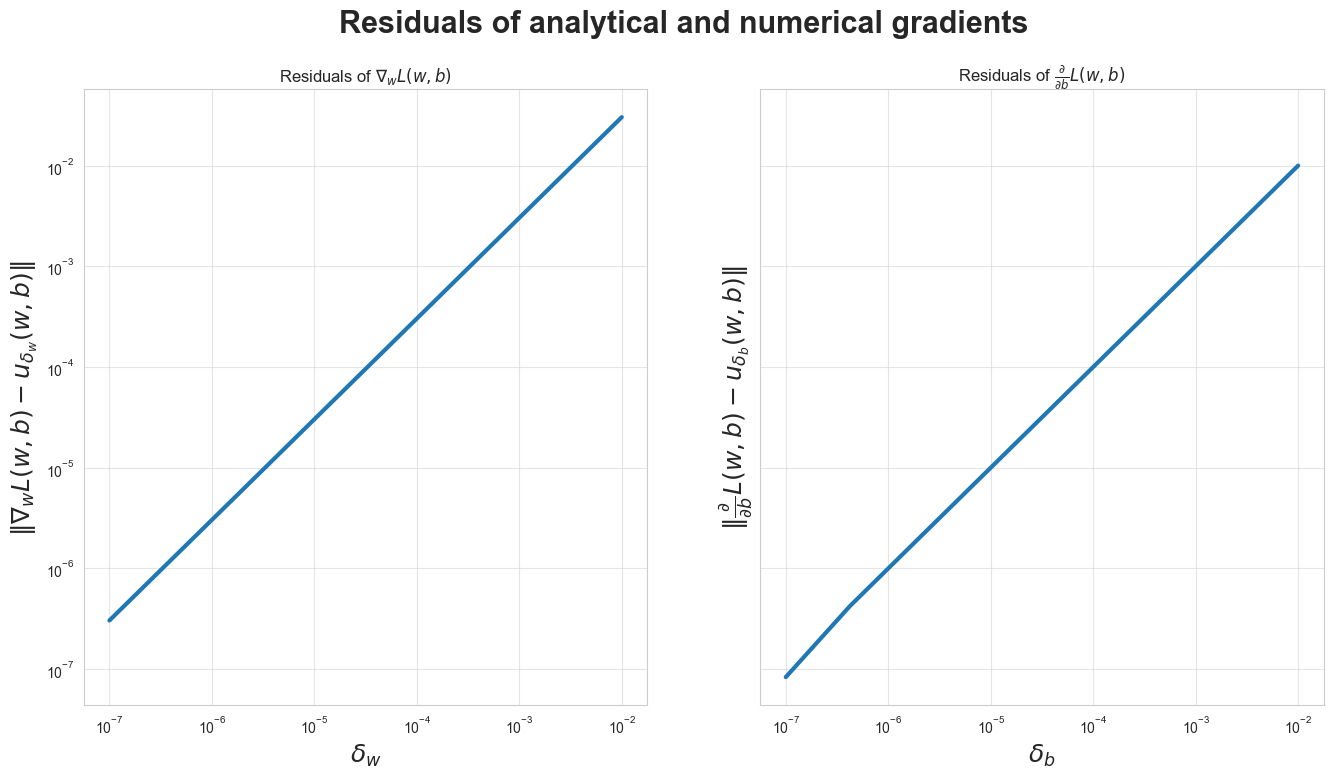

In [100]:
# Question 2


compare_gradients(X_train_subset, y_train_subset, deltas=np.logspace(-7, -2, 9))


In [101]:
def test_lr(X_train, y_train, X_val, y_val, title:str, max_iter = 1500):
  lr_list = np.logspace(-9, -1, 9)

  fig, axs = plt.subplots(3, 3, sharey=True, figsize=(20, 12))
  plt.suptitle(title, fontsize=32)
  plt.tight_layout()
  fig.subplots_adjust(hspace=0.5, top=0.9)
  
  axs = np.ravel(axs)
  for i, lr in enumerate(lr_list):
    cur_linear_reggressor = LinearRegressor(lr)
    train_losses, val_losses = cur_linear_reggressor.fit_with_logs(X_train, y_train, keep_losses=True, X_val=X_val, y_val=y_val, max_iter = max_iter)
    print('lr size = '+str(lr)+', Best train loss = '+str(min(train_losses))+', Best validation loss = '+str(min(val_losses)))

    iterations = np.arange(max_iter + 1)
    axs[i].semilogy(iterations, train_losses, label="Train")
    axs[i].semilogy(iterations, val_losses, label="Validation")
    axs[i].grid(alpha=0.5)
    axs[i].legend()
    axs[i].set_title('lr = '+str(lr))
    axs[i].set_xlabel('iteration')
    axs[i].set_ylabel('MSE')

lr size = 1e-09, Best train loss = 0.07551846941130301, Best validation loss = 0.1036818406876142
lr size = 1e-08, Best train loss = 0.07551652714249535, Best validation loss = 0.10367899554611723
lr size = 1e-07, Best train loss = 0.07549711111838918, Best validation loss = 0.10365055340933477
lr size = 1e-06, Best train loss = 0.0753036153526661, Best validation loss = 0.10336705736295301
lr size = 1e-05, Best train loss = 0.07343322688784362, Best validation loss = 0.10062218534819216
lr size = 0.0001, Best train loss = 0.05967120267788879, Best validation loss = 0.08018952954066955
lr size = 0.001, Best train loss = 0.02607456827815191, Best validation loss = 0.033317376476116746
lr size = 0.01, Best train loss = 0.008823901514808741, Best validation loss = 0.01054320278622521
lr size = 0.1, Best train loss = 0.008847178844184926, Best validation loss = 0.010466781766329933


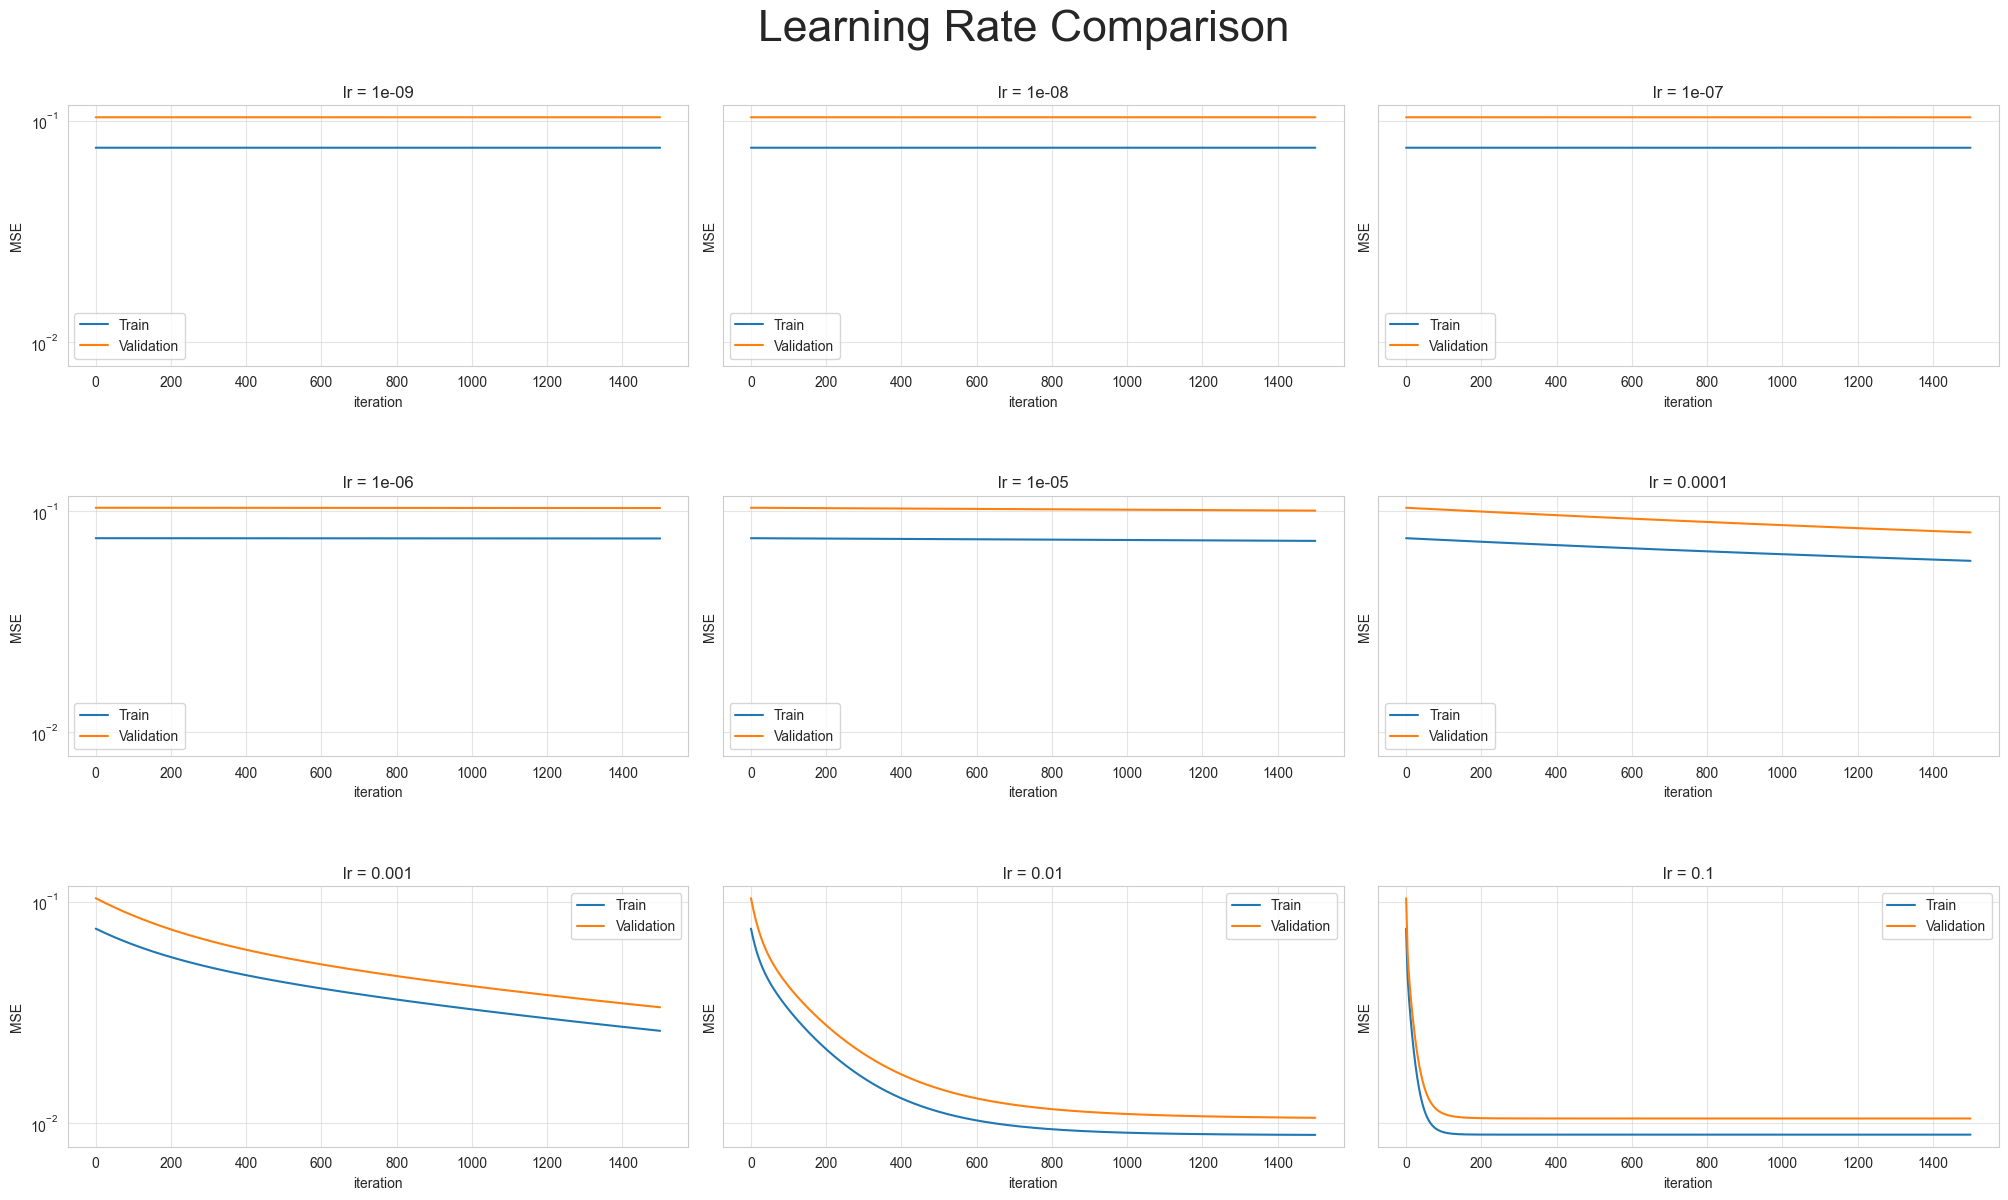

In [102]:
# X_train_subset, X_train_valid, y_train_subset, y_train_valid


test_lr(X_train_subset, y_train_subset, X_train_valid, y_train_valid, "Learning Rate Comparison")

In [103]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

#X_train_subset, X_train_valid, y_train_subset, y_train_valid  = train_test_split(train_X, train_y, test_size=0.2, random_state=123)


dumb_reg = DummyRegressor(strategy='mean')
cross_val_score = cross_validate(dumb_reg, X=train_X, y=train_y, cv = 5 , scoring='neg_mean_squared_error', return_train_score=True)

print("train loss mean:")
print(-cross_val_score['train_score'].mean() )

print("valid loss mean:")
print( -cross_val_score['test_score'].mean() )

#save for later:
dumb_reg = DummyRegressor(strategy='mean')
dumb_reg.fit(train_X, train_y)

train loss mean:
0.07020197010965457
valid loss mean:
0.07041185933040296


DummyRegressor()

In [104]:
# Q5

# We can see from test_lr that a range between e-1 and e-3 is good for us.
lr_logspace = np.logspace(-3, -1, 31)
train_scores = []
valid_scores = []

for lr in lr_logspace:
    curr_linear_reggressor = LinearRegressor(lr)
    curr_score_cross_val = cross_validate(curr_linear_reggressor, X=train_X, y=train_y, cv = 5 , scoring='neg_mean_squared_error', return_train_score=True)
    train_scores.append(-curr_score_cross_val['train_score'].mean())
    valid_scores.append(-curr_score_cross_val['test_score'].mean())


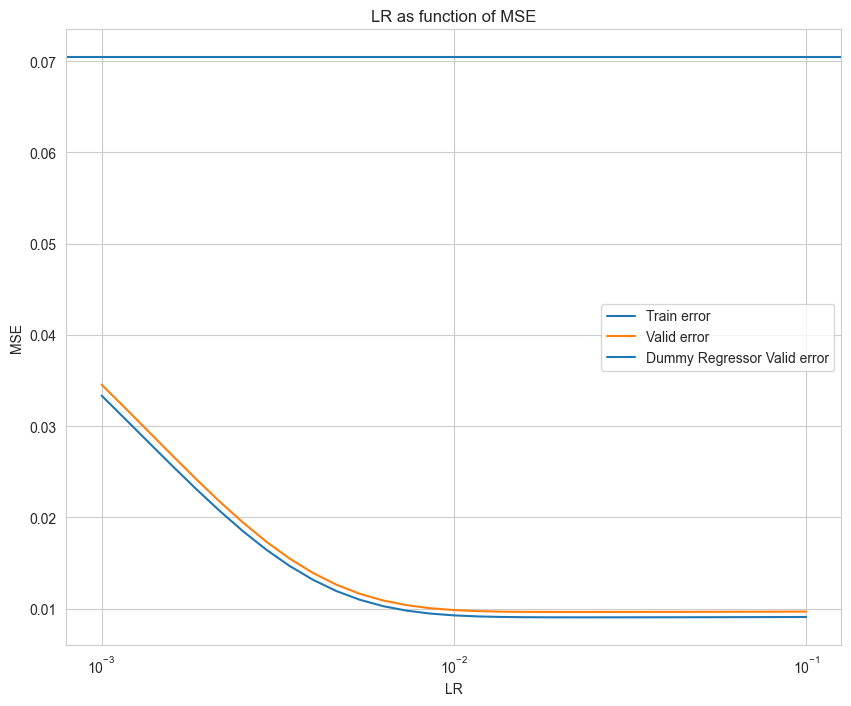

In [105]:
figure, ax = plt.subplots(figsize=(10, 8))
ax.semilogx(lr_logspace, train_scores, label='Train error')
ax.semilogx(lr_logspace, valid_scores, label='Valid error')
ax.axhline(y=0.07041185933040296, label='Dummy Regressor Valid error')
ax.set_xlabel('LR')
ax.set_ylabel('MSE')
ax.set_title('LR as function of MSE')
ax.legend()
plt.show()


In [106]:
optimal_step_size_idx = np.argmin(valid_scores)
optimal_step_size = lr_logspace[optimal_step_size_idx]

print("optimal Valid Error:")
print(valid_scores[optimal_step_size_idx])
print("optimal Train Error:")
print(train_scores[optimal_step_size_idx])
print("optimal LR:")
print(optimal_step_size)

optimal Valid Error:
0.009637031428234372
optimal Train Error:
0.009049982022477634
optimal LR:
0.021544346900318832


In [107]:
# Save the best Linear Regressor For later

optimal_linear_regressor = LinearRegressor(lr=optimal_step_size)
optimal_linear_regressor.fit(train_X, train_y)

LinearRegressor(lr=0.021544346900318832)

In [108]:
from sklearn import linear_model

# section 3
# Q7 

alpha_logspace = np.logspace(-5, 1, 200)
lasso_train_scores = []
lasso_valid_scores = []

for curr_alpha in alpha_logspace:
    curr_lasso_reg = linear_model.Lasso(alpha=curr_alpha, fit_intercept=True)
    curr_score_cross_val = cross_validate(curr_lasso_reg, X=train_X, y=train_y, cv = 5 , scoring='neg_mean_squared_error', return_train_score=True)
    lasso_train_scores.append(-curr_score_cross_val['train_score'].mean())
    lasso_valid_scores.append(-curr_score_cross_val['test_score'].mean())

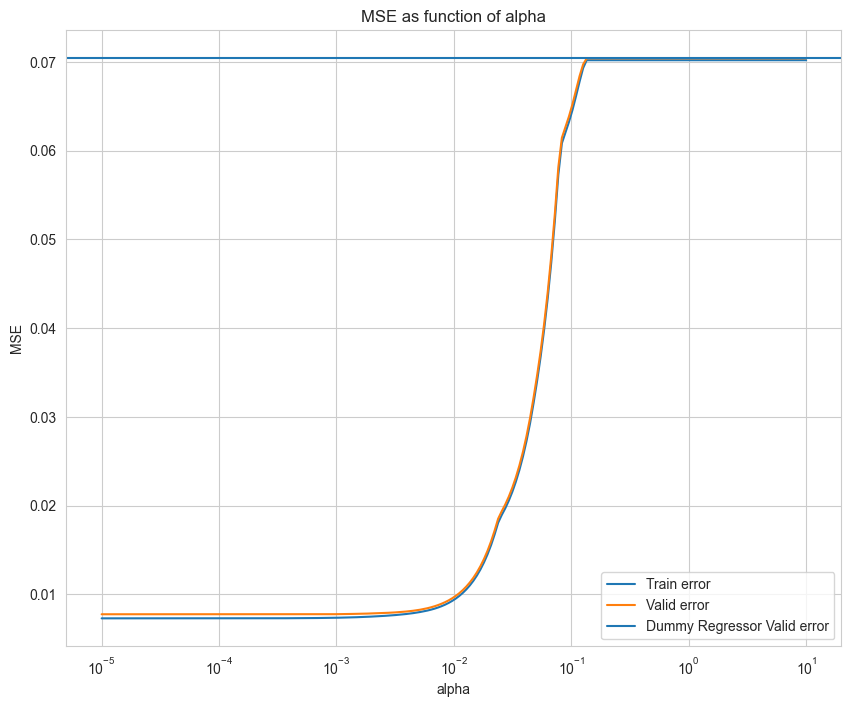

In [109]:
figure2, ax2 = plt.subplots(figsize=(10, 8))
ax2.semilogx(alpha_logspace, lasso_train_scores, label='Train error')
ax2.semilogx(alpha_logspace, lasso_valid_scores, label='Valid error')
ax2.axhline(y=0.07041185933040296, label='Dummy Regressor Valid error')
ax2.set_xlabel('alpha')
ax2.set_ylabel('MSE')
ax2.set_title('MSE as function of alpha')
ax2.legend()
plt.show()

In [110]:

Lasso_optimal_alpha_idx = np.argmin(lasso_valid_scores)
Lasso_optimal_alpha = alpha_logspace[Lasso_optimal_alpha_idx]

print("Lasso Optimal Alpha - Valid Error:")
print(lasso_valid_scores[Lasso_optimal_alpha_idx])
print("Lasso Optimal Alpha - Train Error:")
print(lasso_train_scores[Lasso_optimal_alpha_idx])
print("Optimal Alpha:")
print(Lasso_optimal_alpha)

Lasso Optimal Alpha - Valid Error:
0.007755303598110869
Lasso Optimal Alpha - Train Error:
0.007319608597012884
Optimal Alpha:
0.0003962688638701478


In [111]:
# Task after Q8

optimal_lasso_model = linear_model.Lasso(alpha=Lasso_optimal_alpha, fit_intercept=True)
optimal_lasso_model.fit(train_X, train_y)

Lasso(alpha=0.0003962688638701478)

In [112]:
coeffs_list_absolute = np.argsort(np.abs(optimal_lasso_model.coef_))
coeffs_list_absolute_reverse_top_5 = (   (list(coeffs_list_absolute))   ) [-5:][::-1]  


print(coeffs_list_absolute_reverse_top_5)
print("The following are the five biggest coefficents:")

for idx in coeffs_list_absolute_reverse_top_5:
    print(train_X.columns[idx] + " with a coeff of: " + str(np.abs(optimal_lasso_model.coef_[idx]) ) )
print(train_X.columns[coeffs_list_absolute_reverse_top_5])



[13, 11, 8, 15, 18]
The following are the five biggest coefficents:
PCR_04 with a coeff of: 0.463496941205235
PCR_02 with a coeff of: 0.2527901149279534
sugar_levels with a coeff of: 0.13514775112520705
PCR_06 with a coeff of: 0.050162463221740054
PCR_09 with a coeff of: 0.016407406852982007
Index(['PCR_04', 'PCR_02', 'sugar_levels', 'PCR_06', 'PCR_09'], dtype='object')


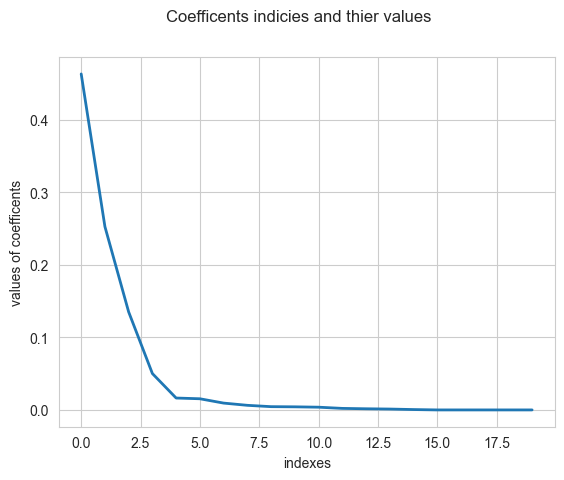

In [113]:
coeffiecents_sorted_values = np.sort(np.abs(optimal_lasso_model.coef_))[::-1]
coeffiecents_indexs = list(range(len(coeffiecents_sorted_values)))

figure, _ = plt.subplots()
plt.plot(coeffiecents_indexs, coeffiecents_sorted_values, lw=2)
plt.ylabel('values of coefficents')
plt.xlabel('indexes')

plt.grid(visible=True)
plt.suptitle("Coefficents indicies and thier values")
plt.show()



In [114]:
print(train_X.columns)

Index(['age', 'sex', 'weight', 'SpecialProperty', 'num_of_siblings',
       'happiness_score', 'household_income', 'conversations_per_day',
       'sugar_levels', 'sport_activity', 'PCR_01', 'PCR_02', 'PCR_03',
       'PCR_04', 'PCR_05', 'PCR_06', 'PCR_07', 'PCR_08', 'PCR_09', 'PCR_10'],
      dtype='object')


In [115]:
print(optimal_lasso_model.coef_)

[-0.01539501  0.00120296  0.          0.00051135  0.00426713 -0.00942788
  0.         -0.00376337  0.13514775  0.00450022 -0.         -0.25279011
 -0.00635055  0.46349694  0.         -0.05016246 -0.          0.00211392
 -0.01640741  0.00158093]


In [116]:

def plot3d(df, colX:str, colY:str, colZ:str, title:str, predictions=None):
  fig = plt.figure(figsize=(20, 7))
  axes = [fig.add_subplot(1, 3, i+1, projection='3d') for i in range(3)]

  palette = sns.color_palette("hls", 2)

  for i,ax in enumerate(axes):
    if predictions is not None:
      ax.scatter3D(df[colX], df[colY], predictions, color=palette[1], s=3)
      ax.scatter3D(df[colX], df[colY], df[colZ], color=palette[0], s=1, 
                   alpha=0.35, depthshade=False)
    else:
      ax.scatter3D(df[colX], df[colY], df[colZ], color=palette[0], s=1)

    ax.set_xlabel(colX)
    ax.set_ylabel(colY)
    ax.xaxis.set_ticklabels([])
    ax.yaxis.set_ticklabels([])
    
    ax.view_init(elev=5., azim=45*i)
  
  axes[0].set_zlabel("\n" + colZ, linespacing=2.2)

  plt.suptitle(title, fontsize=32)
  plt.tight_layout()
  plt.show()

C:\Users\thebo\OneDrive - Technion\2024B\Intro To ML\Major HW1\venv\lib\site-packages\ipykernel_launcher.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


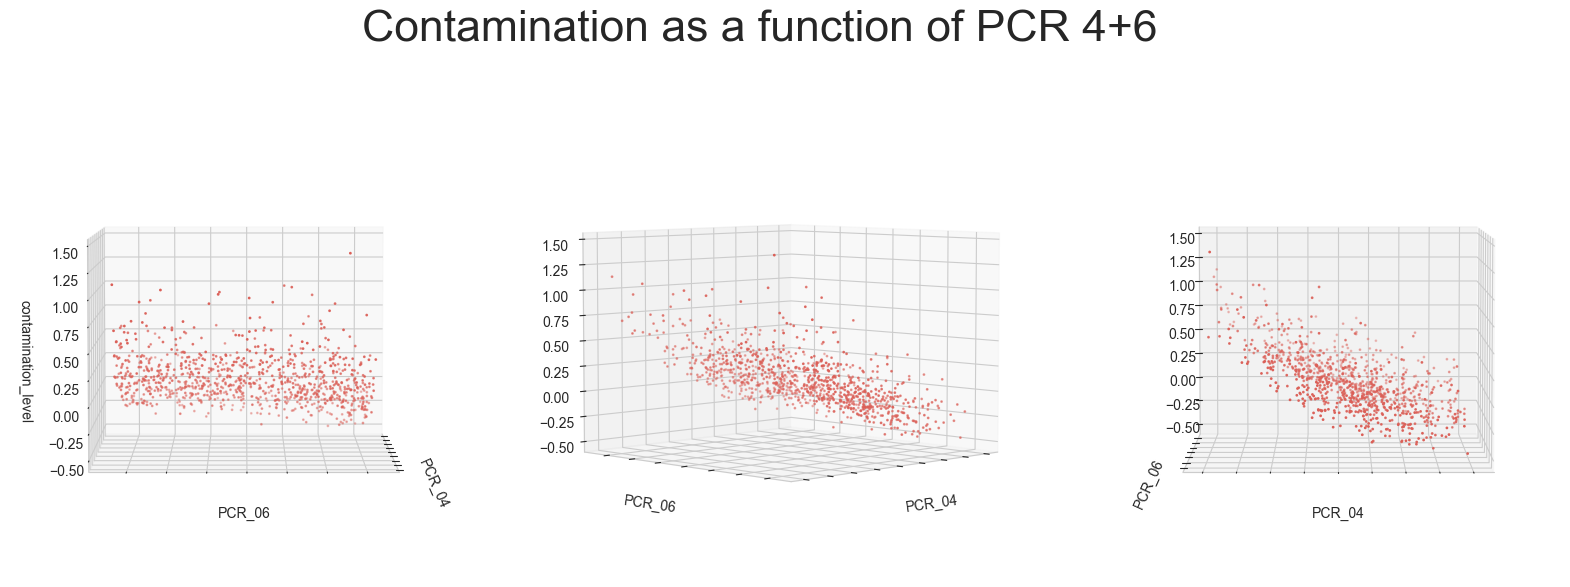

In [117]:

# SECTION 4
# POLYNOMIAL FITTING

sec4_trainX = train_X[['PCR_04','PCR_06']]
sec4_trainy = train_y

plot3d(train_df_prep,'PCR_04','PCR_06','contamination_level', 'Contamination as a function of PCR 4+6')



In [118]:

from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

sec4_pipeline = Pipeline([('feature_mapping', PolynomialFeatures(4)),
                         ('normalization', MinMaxScaler()),
                         ('Lasso', linear_model.Lasso(alpha=0.001, fit_intercept=True))])
    
    


In [119]:

alpha_range = np.logspace(-6, 2, 30)
sec4_train_scores_mean = []
sec4_valid_scores_mean = []

for Lambda in alpha_range:
    sec4_pipeline = Pipeline([('feature_mapping', PolynomialFeatures(4)),
                         ('normalization', MinMaxScaler()),
                         ('Lasso', linear_model.Lasso(alpha=Lambda, fit_intercept=True))])
    
    scores = cross_validate(sec4_pipeline, train_df_prep[['PCR_04','PCR_06']], train_df_prep['contamination_level'], cv=5, return_train_score=True, scoring='neg_mean_squared_error')
    sec4_train_scores_mean.append(np.abs(np.mean(np.array(scores['train_score']))))
    sec4_valid_scores_mean.append(np.abs(np.mean(np.array(scores['test_score']))))

Dummy Valid Loss mean:
0.07041185933040296


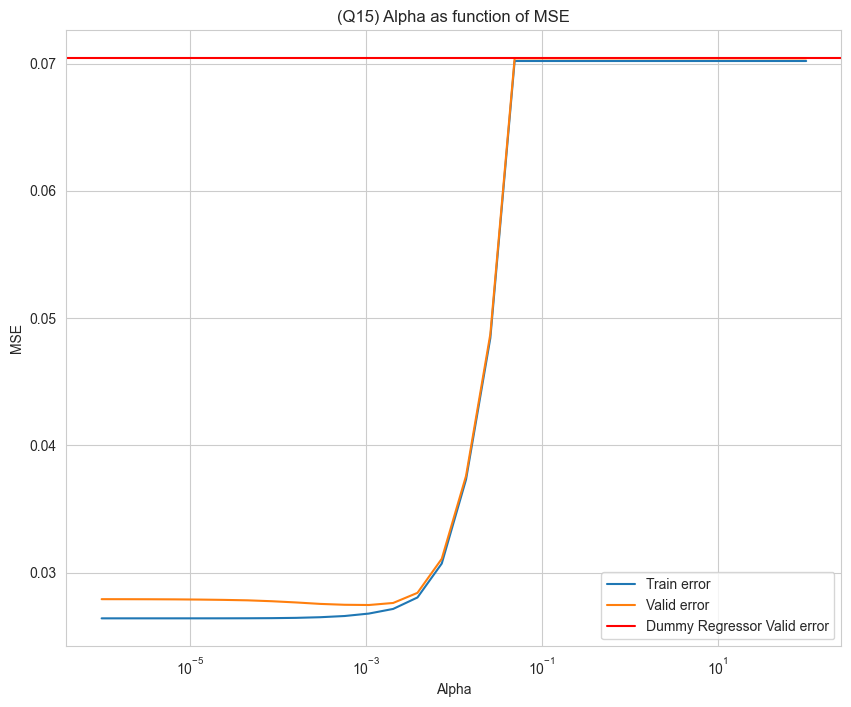

In [120]:
sec4_dumb_reg = DummyRegressor(strategy='mean')
sec4_cross_val_score = cross_validate(sec4_dumb_reg, X=sec4_trainX, y=sec4_trainy, cv = 5 , scoring='neg_mean_squared_error', return_train_score=True)

sec4_dummy_valid_mean = -sec4_cross_val_score['test_score'].mean()
print("Dummy Valid Loss mean:")
print( sec4_dummy_valid_mean )
 
figure, ax = plt.subplots(figsize=(10, 8))
ax.semilogx(alpha_range, sec4_train_scores_mean, label='Train error')
ax.semilogx(alpha_range, sec4_valid_scores_mean, label='Valid error')
ax.axhline(y=sec4_dummy_valid_mean, label='Dummy Regressor Valid error', color='r')
ax.set_xlabel('Alpha')
ax.set_ylabel('MSE')
ax.set_title('(Q15) Alpha as function of MSE')
ax.legend()
plt.show() 


In [121]:
sec4_Lasso_optimal_alpha_idx = np.argmin(sec4_valid_scores_mean)
sec4_Lasso_optimal_alpha = alpha_logspace[sec4_Lasso_optimal_alpha_idx]

print("(Q15) Lasso Optimal Alpha - Valid Error:")
print(sec4_valid_scores_mean[sec4_Lasso_optimal_alpha_idx])
print("Lasso Optimal Alpha - Train Error:")
print(sec4_valid_scores_mean[sec4_Lasso_optimal_alpha_idx])
print("Optimal Alpha:")
print(sec4_Lasso_optimal_alpha)

(Q15) Lasso Optimal Alpha - Valid Error:
0.027468432604160088
Lasso Optimal Alpha - Train Error:
0.027468432604160088
Optimal Alpha:
2.146141197858406e-05


In [122]:
sec4_optimal_lasso_regresssor = Pipeline([('feature_mapping', PolynomialFeatures(4)),
                         ('normalization', MinMaxScaler()),
                         ('Lasso', linear_model.Lasso(alpha=sec4_Lasso_optimal_alpha, fit_intercept=True))])

sec4_optimal_lasso_regresssor.fit(sec4_trainX,sec4_trainy)

Pipeline(steps=[('feature_mapping', PolynomialFeatures(degree=4)),
                ('normalization', MinMaxScaler()),
                ('Lasso', Lasso(alpha=2.146141197858406e-05))])

C:\Users\thebo\OneDrive - Technion\2024B\Intro To ML\Major HW1\venv\lib\site-packages\ipykernel_launcher.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


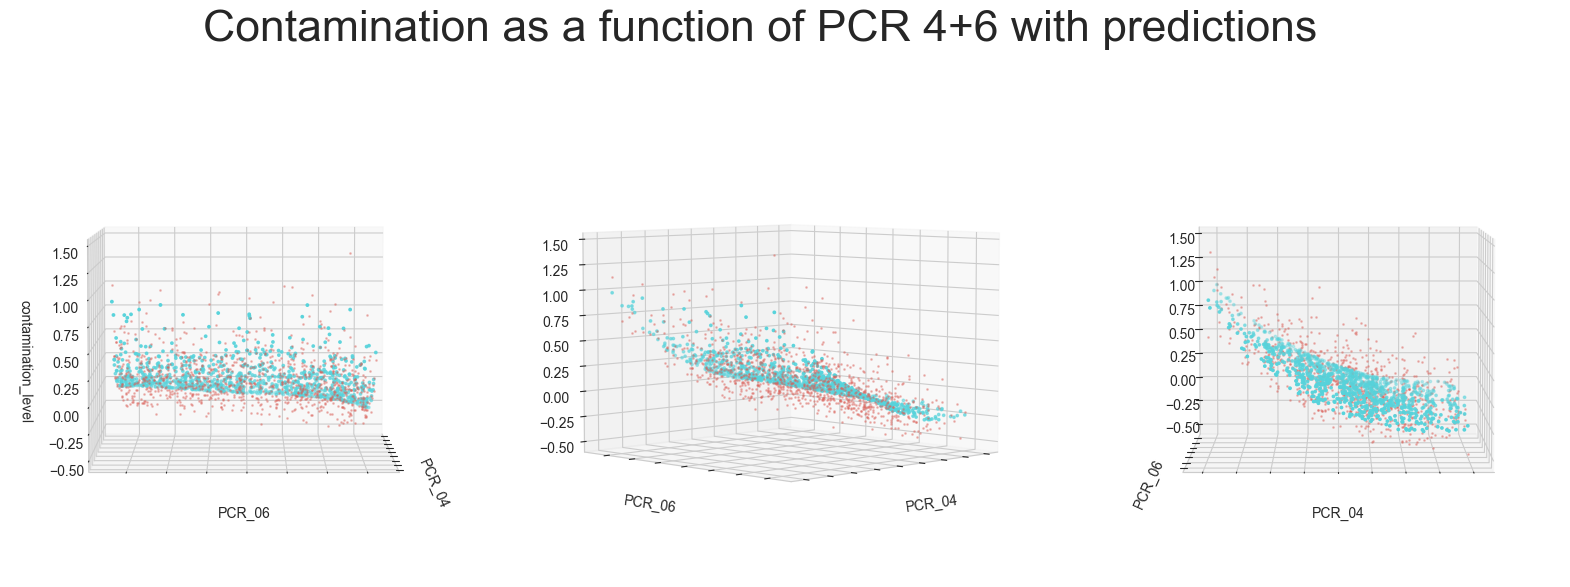

In [123]:
#q16
sec4_testX = test_df_prep[['PCR_04','PCR_06']]
sec4_testy = test_df_prep['contamination_level']

sec4_predictions = sec4_optimal_lasso_regresssor.predict(sec4_trainX)

plot3d(train_df_prep,'PCR_04','PCR_06','contamination_level', 'Contamination as a function of PCR 4+6 with predictions', predictions=sec4_predictions)



In [124]:
from sklearn.ensemble import GradientBoostingRegressor
#section5

sec5_features = ['PCR_01', 'PCR_02', 'PCR_03','PCR_04','PCR_05','PCR_06','PCR_09','PCR_10', 'sugar_levels' ]

sec5_train_X = train_df_prep[sec5_features].copy()
sec5_train_y = train_df_prep['contamination_level'].copy()

sec5_test_X = test_df_prep[sec5_features].copy()
sec5_test_y = test_df_prep['contamination_level'].copy()



In [125]:
#q18

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

# Find dumb regressor score in these selected features.

sec5_dumb_reg = DummyRegressor(strategy='mean')
cross_val_score = cross_validate(sec5_dumb_reg, X=sec5_train_X, y=sec5_train_y, cv = 5 , scoring='neg_mean_squared_error', return_train_score=True)

print("Section 5 Dumb Regressor Train Score Mean:")
print(-cross_val_score['train_score'].mean() )

print("Section 5 Dumb Regressor Validation Score Mean:")
print( -cross_val_score['test_score'].mean() )

sec5_dumb_score = -cross_val_score['test_score'].mean()


Section 5 Dumb Regressor Train Score Mean:
0.07020197010965457
Section 5 Dumb Regressor Validation Score Mean:
0.07041185933040296


In [126]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV

our_GBR = GradientBoostingRegressor(random_state=123, loss='huber')

ranges_grid = [ { 'min_samples_leaf': [2,4,6,8,10], 'learning_rate': np.logspace(-5,0, 5) } ]

sec5_GS = GridSearchCV(param_grid=ranges_grid, estimator=our_GBR,
                           cv=5, scoring='neg_mean_squared_error',
                           n_jobs=None)

sec5_GS.fit(sec5_train_X, sec5_train_y) 

sec5_GBR_model_best = sec5_GS.best_estimator_
sec5_GBR_params_best = sec5_GS.best_params_
sec5_GBR_score_best_train = -sec5_GS.best_score_


sec5_GBR_test_preds =  sec5_GBR_model_best.predict(sec5_test_X)
sec5_GBR_valid_error = mean_squared_error(sec5_test_y, sec5_GBR_test_preds)

# now that we have the valid error results of the optimal GBR model, we make the heatmap


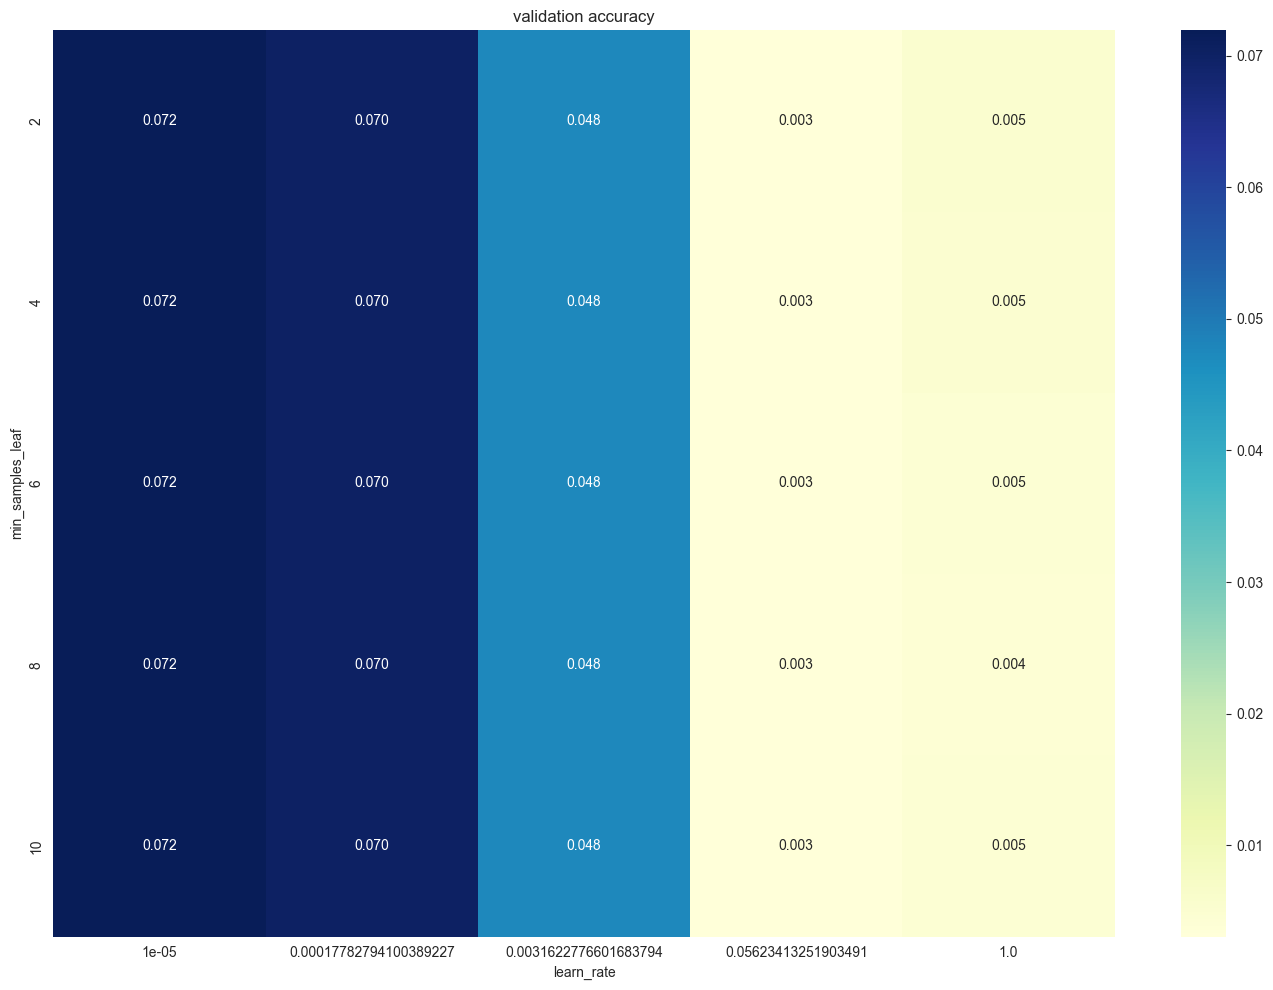

In [127]:
#HEATMAPP

heatmap_matrix = -(pd.DataFrame(sec5_GS.cv_results_).pivot(index='param_min_samples_leaf', columns='param_learning_rate', values='mean_test_score'))


plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_matrix, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("validation accuracy")
plt.xlabel("learn_rate")
plt.ylabel("min_samples_leaf")
plt.tight_layout()
plt.show()

In [128]:
# Find best Train/Valid error , and thier respective parameters:

print('Gradient Boost Best Training Error')
print(sec5_GBR_score_best_train)
print('Gradient Boost Best Validation Error')
print(sec5_GBR_valid_error)
print('Gradient Boost Best Hyper Paremeters')
print(sec5_GBR_params_best)



Gradient Boost Best Training Error
0.0030703755291724114
Gradient Boost Best Validation Error
0.0016542936425426866
Gradient Boost Best Hyper Paremeters
{'learning_rate': 0.05623413251903491, 'min_samples_leaf': 10}


In [129]:
sec5_saved_gbm = GradientBoostingRegressor(learning_rate=0.05623413251903491
, min_samples_leaf=10,loss='huber',random_state=123)
sec5_saved_gbm.fit(sec5_train_X, sec5_train_y)

GradientBoostingRegressor(learning_rate=0.05623413251903491, loss='huber',
                          min_samples_leaf=10, random_state=123)

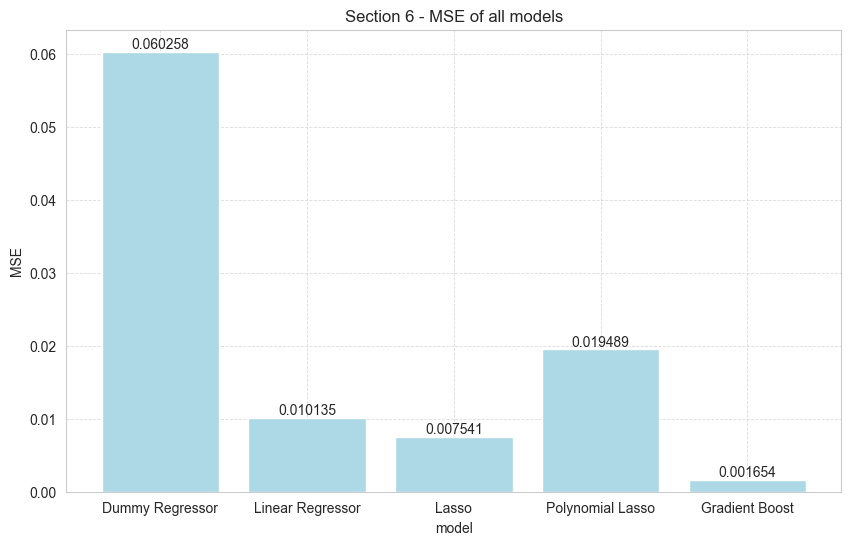

In [132]:
sec_23_test_X = test_df_prep.drop(['contamination_level'], axis=1)
sec_23_test_y = test_df_prep['contamination_level']

#sec4_testX = test_df_prep[['PCR_04','PCR_06']]
#sec4_testy = test_df_prep['contamination_level']

# sec5_test_X
# sec5_test_y

#Models saved from before:
# dumb_reg
# optimal_linear_regressor
# optimal_lasso_model
# sec4_optimal_lasso_regresssor
# sec5_saved_gbm

names_of_models = ['Dummy Regressor', 'Linear Regressor', 'Lasso'
                   ,'Polynomial Lasso','Gradient Boost']

sec6_preds = [
    dumb_reg.predict(sec_23_test_X),
    optimal_linear_regressor.predict(sec_23_test_X),
    optimal_lasso_model.predict(sec_23_test_X),
    sec4_optimal_lasso_regresssor.predict(sec4_testX),
    sec5_saved_gbm.predict(sec5_test_X)
]

sec6_test_results = [
    mean_squared_error(sec_23_test_y, sec6_preds[0]),
    mean_squared_error(sec_23_test_y, sec6_preds[1]),
    mean_squared_error(sec_23_test_y, sec6_preds[2]),
    mean_squared_error(sec4_testy, sec6_preds[3]),
    mean_squared_error(sec5_test_y, sec6_preds[4])
]

plt.figure(figsize=(10, 6))
bars = plt.bar(names_of_models, sec6_test_results, color='lightblue')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:.6f}', ha='center', va='bottom')

plt.title('Section 6 - MSE of all models')
plt.xlabel('model')
plt.ylabel('MSE')
plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
plt.show()

